# EES1133 Lab 3: Energy Balance Models with Water Vapour with `climlab`

Adapted from notes by:
[Brian E. J. Rose](http://www.atmos.albany.edu/facstaff/brose/index.html), University at Albany

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

You may or may not need to re-install climlab

In [ ]:
!mamba install climlab

In [ ]:
import xarray as xr
import climlab

## Preface

Most of this lab is filled in for you. There are a few parts that I ask you to fill in. Be sure to follow along. If anything is unclear, please come to office hours to discuss.

____________
<a id='section1'></a>

## 1. A Radiative-Convective Equilibrium (RCE) Model using the RRTMG radiation module
____________

`climlab` provides two different ***spectrally-dependent*** (aka ***wavelength-dependent***) "Global Climate Model (GCM)-grade" radiation codes:

- The [CAM3 radiation module](https://climlab.readthedocs.io/en/latest/api/climlab.radiation.CAM3.html) from NCAR
- The [RRTMG (Rapid Radiative Transfer Model)](https://climlab.readthedocs.io/en/latest/api/climlab.radiation.RRTMG.html?highlight=RRTMG) which is used in many current GCMs.

The links above take you to the online [climlab documentation](http://climlab.readthedocs.io/en/latest/intro.html).

In today's lab, we will use the RRTMG radiation code to examine the role of water vapour in a simple column model.

### Reflection Question: 

#### What do we mean by ***spectrally-dependent*** or ***wavelength-dependent***?

We will need to initialize our column model with a realistic vertical profile of water vapour. To do this, we will use a water vapour from a pre-industrical control (year 1850 constant forcings) run of the Community Earth System Model (CESM) GCM from the National Center for Atmospheric Research (NCAR) in Boulder, Colorado.

I have already downloaded this data for you.

In [3]:
#  Load the water vapour data
Qglobal_q = np.genfromtxt('Qglobal_q.csv',delimiter=',') #units are kg of water vapour/kg of atmosphere (kg/kg)

#  Load in the model levels that correspond to the water vapour data
Qglobal_lev = np.genfromtxt('Qglobal_lev.csv',delimiter=',')

In [8]:
print(Qglobal_q)

[2.16255006e-06 2.15911701e-06 2.14943023e-06 2.13379934e-06
 2.11993381e-06 2.11149790e-06 2.09546420e-06 2.11827126e-06
 2.44143531e-06 3.15595114e-06 5.05748229e-06 9.66307595e-06
 2.10024053e-05 4.80359029e-05 1.05611312e-04 2.11799800e-04
 3.93558531e-04 7.10659654e-04 1.34089154e-03 2.05090474e-03
 3.16241947e-03 4.96104823e-03 6.60819328e-03 8.36425275e-03
 9.36470014e-03 9.62937462e-03]


One of the key messages of this lab is to demonstrate the relative importance of the water vapour and well-mixed GHGs, such as CO$_2$. Let's start with the full model and then isolate the different GHGs.

____________
<a id='section1'></a>

### 1.1 A Spectrally-Dependent RCE Model
____________

Here we initialize our RCE column model using the same levels as the water vapour data from the GCM and using the water vapour values from the GCM.

We also set the lapse rate for convective adjustment to 6.5 K/km

Run the cell below. 

In [5]:
#  Make a radiative-convective equilibrium column model on same vertical domain as the NCAR GCM

state = climlab.column_state(lev=Qglobal_lev, water_depth=2.5) #  initialize the model with the CESM levels
rad = climlab.radiation.RRTMG(name='Radiation',
                              state=state, 
                              specific_humidity=Qglobal_q,  # set specific humidity to GCM values
                              timestep = climlab.constants.seconds_per_day,
                              albedo = 0.25,  # tuned to give reasonable ASR for reference cloud-free model
                             )
#  Add convective adjustment
conv = climlab.convection.ConvectiveAdjustment(name='Convection',
                                               state=state,
                                               adj_lapse_rate=6.5, #  use moist-adiabatic lapse rate
                                               timestep=rad.timestep,)
rcm = rad + conv
rcm.name = 'Radiative-Convective Model with Moisture'

In [6]:
# show the details of the model processes. We see a radiation component and a convection component
print(rcm)

climlab Process of type <class 'climlab.process.time_dependent_process.TimeDependentProcess'>. 
State variables and domain shapes: 
  Ts: (1,) 
  Tatm: (26,) 
The subprocess tree: 
Radiative-Convective Model with Moisture: <class 'climlab.process.time_dependent_process.TimeDependentProcess'>
   Radiation: <class 'climlab.radiation.rrtm.rrtmg.RRTMG'>
      SW: <class 'climlab.radiation.rrtm.rrtmg_sw.RRTMG_SW'>
      LW: <class 'climlab.radiation.rrtm.rrtmg_lw.RRTMG_LW'>
   Convection: <class 'climlab.convection.convadj.ConvectiveAdjustment'>



We have specified the water vapour concentrations. But, let's take a look at the default concentrations of well-mixed GHGs and the other important absorbers.

Uncomment and run the cell below.

In [13]:
#rcm.subprocess['Radiation'].absorber_vmr

We have CO$_2$, CH$_4$ (methane), N$_2$0 (nitrous oxide), molecular oxygen and ozone (tropospheric and stratospheric). The concentrations of these gases are shown in kg/kg. These concentrations all correspond to pre-industrial values.

Now, let's take a look at the water vapour. This should look just like the values we specified.

Uncomment and run the cell below.

In [14]:
#rcm.subprocess['Radiation'].specific_humidity

As we have done in the past, we can use the "integrate_years" function to step the model forward to equilibrium.

Uncomment and run the cell below.

In [28]:
#rcm.integrate_years(5)

Notice that this took a bit longer to integrate than with our simple Grey Gas column model. The radiative transfer is now more complex and, therefore, takes longer to compute.

In the usual way, let's check that the model has reached equilibrium.

Fill this part in. Use the same syntax that we used in Lab 3.

In [16]:
# check that the model has reached equilibrium

What is the surface temperature? Fill this part in.

In [17]:
# display the surface temperature

Ok, we'll set this model aside for now and come back to it later.

____________
<a id='section1'></a>

### 1.2 RCE with no Moisture
____________

Now, we are going to construct a similar model but with ***no water vapour***. We will examine what the equilibrium temperature profile looks like for this model compared to the full model.

Run the cell below. Notice how we have changed the specific_humidity parameter to be zero.

In [16]:
# Modify the code below to set specific humidity to zero
state = climlab.column_state(lev=Qglobal_lev, water_depth=2.5)
rad = climlab.radiation.RRTMG(name='Radiation',
                              state=state, 
                              specific_humidity=0.0, 
                              timestep = climlab.constants.seconds_per_day,
                              albedo = 0.25,  # tuned to give reasonable ASR for reference cloud-free model
                             )
conv = climlab.convection.ConvectiveAdjustment(name='Convection',
                                               state=state,
                                               adj_lapse_rate=6.5,
                                               timestep=rad.timestep,)
rcm_noh2o = rad + conv #  Notice that we have given the model a new name
rcm_noh2o.name = 'Radiative-Convective Model with no Moisture'

Opened data from /Users/Karen/anaconda3/lib/python3.7/site-packages/climlab/radiation/data/ozone/apeozone_cam3_5_54.nc


Let's check that the model has specific humidity values set to zero.

Uncomment and run the cell below.

In [17]:
#rcm_noh2o.subprocess['Radiation'].specific_humidity

Now, we can integrate the model to equilibrium.

Uncomment and run the cell below.

In [18]:
#rcm_noh2o.integrate_years(5)

Integrating for 1826 steps, 1826.2110000000002 days, or 5 years.
Total elapsed time is 4.999422301147019 years.


Let's check that the model has reached equilibrium. Fill in this part.

In [19]:
# check that the model has reached equilibrium

What is the new surface temperature? Fill in this part.

In [20]:
# display the surface temperature

Again, we'll set this model aside for now and come back to it later.

____________
<a id='section1'></a>

### 1.3 RCE with no CO2
____________

Finally, we are going to construct a model similar to the first with water vapour but with no CO2. We will compare what the equilibrium temperature profile looks like for this model compared to the full model.

Run the cell below.

In [21]:
state = climlab.column_state(lev=Qglobal_lev, water_depth=2.5)
rad = climlab.radiation.RRTMG(name='Radiation',
                              state=state, 
                              specific_humidity=Qglobal_q,
                              timestep = climlab.constants.seconds_per_day,
                              albedo = 0.25,  # tuned to give reasonable ASR for reference cloud-free model
                             )
conv = climlab.convection.ConvectiveAdjustment(name='Convection',
                                               state=state,
                                               adj_lapse_rate=6.5,
                                               timestep=rad.timestep,)
rcm_noco2 = rad + conv #  Notice that we have given the model a new name
rcm_noco2.name = 'Radiative-Convective Model with no CO2'

Opened data from /Users/Karen/anaconda3/lib/python3.7/site-packages/climlab/radiation/data/ozone/apeozone_cam3_5_54.nc


Now, we need to set CO$_2$ concentrations to zero.

Run the cell below.

In [22]:
# Set CO2 to zero. Uncomment the line below and complete setting CO2 to zero
rcm_noco2.subprocess['Radiation'].absorber_vmr['CO2'] = 0.0

Now, we can integrate the model to equilibrium.

Uncomment and run the cell below.

In [24]:
#rcm_noco2.integrate_years(5)

Let's check that the model has reached equilibrium. Fill in this part.

In [ ]:
# check that the model has reached equilibrium

What is the new surface temperature? Fill in this part.

In [ ]:
# display the surface temperature

Now let's plot all three temperature profiles together.

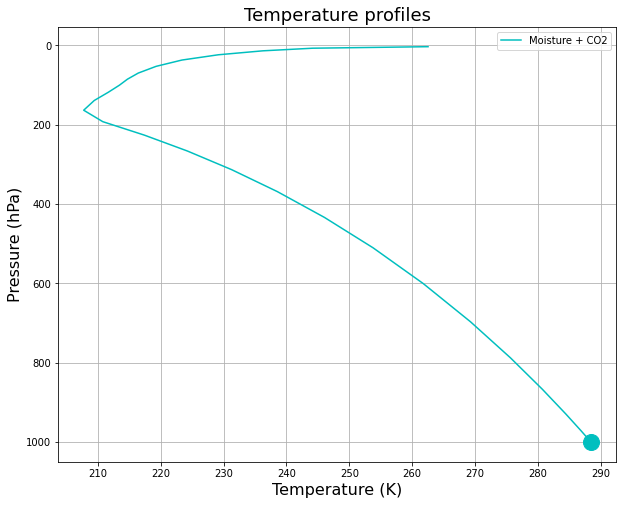

In [29]:
# plot all three temperature profiles. Uncomment and fill in the lines below.

fig, ax = plt.subplots(figsize=(10,8))

# plot model with both CO2 and Moisture
ax.plot( rcm.Tatm, rcm.lev, 'c-', label='Moisture + CO2' )
ax.plot( rcm.Ts, climlab.constants.ps, 'co', markersize=16 )

# plot model with Moisture and no CO2 in the same way as above
#ax.plot( ,'y-',label='Moisture but no CO2' )
#ax.plot( ,'yo',markersize=16 )

# plot model with CO2 but no Moisture in the same way as above
#ax.plot( , 'm-',label='CO2 but no Moisture')
#ax.plot( , 'mo',markersize=16)

ax.plot( markersize=16 )
ax.invert_yaxis()
ax.set_xlabel('Temperature (K)', fontsize=16)
ax.set_ylabel('Pressure (hPa)', fontsize=16 )
ax.set_title('Temperature profiles', fontsize = 18)
ax.grid()
ax.legend()

How do the three temperature profiles differ? Which is the warmest? Which is the coldest?

____________
<a id='section1'></a>

## 2. Radiative Forcing
____________

Now, let's explore the concept of radiative forcing by doubling CO$_2$.

Run the cell below.

In [30]:
# Make an exact clone of the full model with same temperatures
rcm_2xCO2 = climlab.process_like(rcm)
rcm_2xCO2.name = 'Radiative-Convective Model (2xCO2 initial)'

Uncomment and run the cell below.

In [34]:
# Recall that the CO2 concentration is:
#rcm_2xCO2.subprocess['Radiation'].absorber_vmr['CO2']

In [32]:
# Now double it!
rcm_2xCO2.subprocess['Radiation'].absorber_vmr['CO2'] *=2

Uncomment and run the cell below.

In [35]:
# Confirm new doubled concentration
#rcm_2xCO2.subprocess['Radiation'].absorber_vmr['CO2']

### Instantaneous radiative forcing

The simplest measure of radiative forcing is **the instantaneous change** in the energy budget **before the temperatures have a chance to adjust**.

To get this we need to call the `compute_diagnostics` method, but not any forward timestep.

Run the cell below.

In [59]:
rcm_2xCO2.compute_diagnostics()

Now take a look at the changes in the SW and LW budgets, i.e. look at the the change in ASR and OLR between the doubled CO2 run and the baseline run.

Uncomment and run the cell below.

In [62]:
# Difference in ASR between rcm_2xCO2 and rcm
#rcm_2xCO2.ASR - rcm.ASR

How much did the fluxes change when we doubled CO2?

Uncomment and run the cell below.

In [51]:
# Difference in OLR between rcm_2xCO2 and rcm
#rcm_2xCO2.OLR - rcm.OLR

So what is instantaneous radiative forcing for the doubling of CO$_2$? The IRF is the total change in **NET TOA** radiative flux.

Uncomment, fill in and run the cell below.

In [63]:
# Compute IRF

#DeltaR_instant = 
#print(DeltaR_instant)

As we can see above, almost all of the radiative forcing appears in the longwave. We have made the atmosphere **more optically thick** by adding CO$_2$.

Think about this the same way we increased the absorptivity / emissivity parameter $\epsilon$ in the simple grey-gas model.

### Statosphere-adjusted radiative forcing

The point of measuring radiative forcing is that it should give us some information about how much global warming we should expect from a particular forcing agent.

We will need to use our model to quantify the **eventual** temperature change associated with this forcing.

It turns out, for reasons we won't get into here, that a more useful measure of the global warming impact of a forcing agent comes from thinking about **changes in radiative flux at the tropopause** rather than the Top-of-Atmosphere (TOA). Once the stratospheric temperature has adjusted the TOA fluxes represent the change in radiative flux at the tropopause. One of the reasons that allowing the stratospheric temperatures to adjust makes sense is that these temperature adjust relatively quickly, on the order of several months (contrast this with the ocean for example, think about our simple models in previous labs that took years to equilibrate).

The idea here is that we will **let the stratosphere adjust to the extra CO$_2$** while **holding the troposphere and surface temperatures fixed**.

In this model levels 0 through 12 are in the statosphere; levels 13 and larger are in the troposphere:

Uncomment and run the cell below.

In [7]:
# tropospheric pressure levels
#rcm.lev[13:]

So to compute stratosphere-adjusted forcing, we'll timestep the model, but continually reset the temperatures to their reference values below 226 hPa, roughly tropopause height:

Run the cell below.

In [37]:
rcm_2xCO2_strat = climlab.process_like(rcm_2xCO2)
rcm_2xCO2_strat.name = 'Radiative-Convective Model (2xCO2 stratosphere-adjusted)'
for n in range(1000):
    rcm_2xCO2_strat.step_forward()
    # hold tropospheric and surface temperatures fixed
    rcm_2xCO2_strat.Tatm[13:] = rcm.Tatm[13:]
    rcm_2xCO2_strat.Ts[:] = rcm.Ts[:]

Now we can compute the stratosphere-adjusted radiative forcing for the doubling of CO2:

Uncomment, fill in and run the cell below.

In [73]:
# Compute strat-adjusted RF just like we did above for the IRF (total change in **NET TOA** radiative flux)

#DeltaR = 
#print(DeltaR)

Do we get a larger or smaller radiative forcing compared to the IRF? Why? Take a look at the stratospheric temperatures for a clue.

Uncomment and run the cell below.

In [74]:
# Difference between strat-adjusted stratospheric temperatures and unequilibrated 2xCO2 temperatures.
#rcm_2xCO2_strat.Tatm[0:13] - rcm_2xCO2.Tatm[0:13]

Did the temperatures in the stratosphere warm up or cool down in response to a doubling of CO$_2$? How does the change in temperature affect the longwave radiative emission?

____________

<a id='section2'></a>

## 3. Equilibrium climate sensitivity (without feedback)
____________


We now ask the question: How much warming will we get (eventually) in response to this positive radiative forcing?

We define the **Equilibrium Climate Sensitivity** (denoted **ECS** or $\Delta T_{2xCO2}$):

*The global mean surface warming necessary to balance the planetary energy budget after a doubling of atmospheric CO$_2$.*

We will talk about this in more detail in the next Lecture.

We can go ahead and calculate ECS in our single-column model:

Run the cell below.

In [40]:
rcm_2xCO2_eq = climlab.process_like(rcm_2xCO2_strat)
rcm_2xCO2_eq.name = 'Radiative-Convective Model (2xCO2 equilibrium)'
rcm_2xCO2_eq.integrate_years(5)

In [39]:
# are we close to equilibrium? Check ASR-OLR

### Calculate the ECS

It is just the difference in surface temperature between rcm_2xCO2_eq and rcm:

Uncomment, fill in and run the cell below.

In [83]:
# Compute the difference in surface temperature between rcm_2xCO2_eq and rcm.
#ECS_nofeedback = 
#print(ECS_nofeedback)

Doubling CO$_2$ in this model causes a warming at equilibrium.

What about the energy budget? 

Remember that we have let the model warm up to its new equilibrium! 

If we look at the differences between the two equilibrium states (before and after doubling CO$_2$), we should find only very small and offsetting changes in SW and LW:

Fill in the two cells below and run.

In [78]:
# Difference in OLR

In [79]:
# Difference in ASR

The climate sensitivity we've just calculated is the warming that we would have *if there were no other changes (feedbacks) in response to the CO$_2$ induced warming!*

____________
<a id='section3'></a>

## 4. The feedback concept
____________

A climate feedback is a process that will either amplify or reduce the effect of a climate forcing. We will dicuss climate feedbacks in detail next lecture.

### Example: the water vapor feedback

The capacity of the atmosphere to hold water vapor (saturation specific humidity) increases exponentially with temperature. Warming is thus accompanied by moistening (more water vapor), which leads to more warming due to the enhanced water vapor greenhouse effect.

**Do we call this a positive or a negative feedback?**

We can **parameterize** this feedback in the column model by insisting that the **relative humidity remain fixed** as the column warms. This is actually a reasonable assumption as we will see next lecture.

Run the cell below.

In [41]:
#  actual specific humidity
q = rcm.subprocess['Radiation'].specific_humidity

#  saturation specific humidity (a function of temperature and pressure)
qsat = climlab.utils.thermo.qsat(rcm.Tatm, rcm.lev)  # climlab has its own function to compute qsat

Use q and qsat to compute the relative humidity.

Uncomment, fill in and run the cell below.

In [89]:
#  Compute the Relative humidity
#rh = 

Uncomment the `ax2.plot()` line and add relative humidity to the plot below.

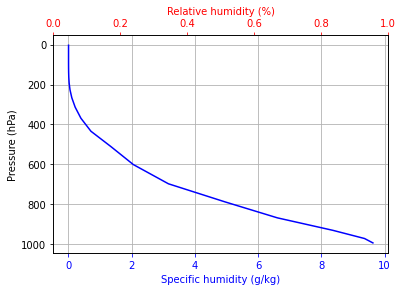

In [42]:
# Plot relative humidity in percent and the humidity in g/kg
# Be sure to uncomment the rh plotting line below
fig,ax = plt.subplots()
ax.plot(q*1000, rcm.lev, 'b-')
ax.invert_yaxis()
ax.grid()
ax.set_ylabel('Pressure (hPa)')
ax.set_xlabel('Specific humidity (g/kg)', color='b')

#  Add relative humidity to the plot
ax.tick_params('x', colors='b')
ax2 = ax.twiny()  # this is a handy plotting tool to allow for multiple axes on the same plot
#ax2.plot(, 'r-') # plot RH
ax2.set_xlabel('Relative humidity (%)', color='r')
ax2.tick_params('x', colors='r')

###  A radiative-convective model with fixed relative humidity

In [99]:
# Make a clone of our doubled CO2 model
rcm_2xCO2_h2o = climlab.process_like(rcm_2xCO2)

We will now force the model to have a water vapour feedback by resetting the specific humidity at each time step and looping over many time steps.

Uncomment and fill in the line below that specifies the new specific humidity. Then run the cell.

In [93]:
for n in range(2000):
    # At every timestep
    # we calculate the new saturation specific humidity for the new temperature
    # and change the water vapor in the radiation model
    # so that relative humidity is always the same
    
    # compute the saturation specific humidity given the temperatures
    qsat = climlab.utils.thermo.qsat(rcm_2xCO2_h2o.Tatm, rcm_2xCO2_h2o.lev)
    
    # compute the new specific humidity using rh
    #rcm_2xCO2_h2o.subprocess['Radiation'].specific_humidity[:] =     # what goes here?
    
    # step the model forward and compute the new temperature
    rcm_2xCO2_h2o.step_forward()

To save the new specific humidity for later, run the cell below.

In [45]:
# save the new specific humidity and add to plot below
q_new = rcm_2xCO2_h2o.subprocess['Radiation'].specific_humidity

Uncomment the `ax.plot()` line and add new specific humidity to the plot below.

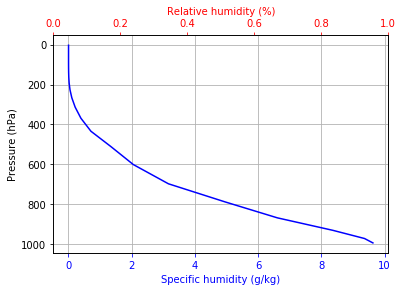

In [94]:
# Add the new water vapour profile to the previous plot. 
fig,ax = plt.subplots()
ax.plot(q*1000, rcm.lev, 'b-')

# Add q_new to plot
#ax.plot(, 'c-')
ax.invert_yaxis()
ax.grid()
ax.set_ylabel('Pressure (hPa)')
ax.set_xlabel('Specific humidity (g/kg)', color='b')
ax.tick_params('x', colors='b')

#  Add relative humidity to the plot
ax2 = ax.twiny()
#ax2.plot(, 'r-')
ax2.set_xlabel('Relative humidity (%)', color='r')
ax2.tick_params('x', colors='r')

Fill in and run the cell below.

In [46]:
# Check for energy balance

What is the Equilibrium Climate Sensitivity (ECS) of this new model?

Uncomment, fill in and run the cell below.

In [97]:
# Difference in surface temperature between rcm_2xCO2_h2o and rcm

#ECS = 
#print(ECS)

By how much does the model warm up now?

You should find a pretty big difference! We can define the increase in ECS as the Gain (terminology borrowed from engineering).

Uncomment and run the cell below.

In [96]:
# Calculate the Gain

#Gain = ECS/ECS_nofeedback
#print(Gain)